# **Plant pest classification**

Run cells in order on Google Colab (GPU runtime recommended). Upload plant_pests_cleaned.zip when prompted. The ZIP contains the cleaning manifest. This notebook implements a frozen ImageNet feature extractor, training-only augmentation and a validation-selected SVM; the held-out test set is used only in the final evaluation. No results are pre-filled.

In [1]:
from google.colab import files
uploaded = files.upload()

Saving plant_pests_cleaned.zip to plant_pests_cleaned.zip


In [2]:
import os

print(os.path.exists('/content/plant_pests_cleaned.zip'))

True


In [3]:
from pathlib import Path
import zipfile, io, re, json, random
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)
import joblib
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# Upload the cleaned archive (or place it in the notebook working directory).
archive = Path('plant_pests_cleaned.zip')
if not archive.exists():
    from google.colab import files
    files.upload()
assert archive.exists(), 'Upload plant_pests_cleaned.zip first.'
root = Path('pest_data')
root.mkdir(exist_ok=True)
with zipfile.ZipFile(archive) as z:
    z.extractall(root)
manifest = pd.read_csv(root / 'cleaning_manifest.csv')
display(manifest.action.value_counts())
classes = ['Aphids', 'Mealy Bugs', 'Spider Mites']
records = []
for label in classes:
    for path in sorted((root / 'ML' / label).iterdir()):
        with Image.open(path) as im:
            im.verify()
        records.append({'path': str(path), 'label': label})
df = pd.DataFrame(records)
display(df.label.value_counts())
assert len(df) == 441

,count
action,
retained,433
excluded,10
converted,8


,count
label,
Aphids,149
Mealy Bugs,148
Spider Mites,144


### **Split by class and recognizable photo series**

Filename-based groups keep obvious related photographs together where possible. These are conservative heuristics, not verified source identifiers. Inspect the grouping and adjust before training if you know additional source relationships.

In [5]:
# Explicit filename patterns for likely same-source image series.
series = [r'^2019-10-23-', r'^articles-pests-diseases-aphids-', r'^aphids[123]_850',
          r'^oleander aphids ', r'^mealybugs-\d{2}(?:-|\.)',
          r'^mealy-bug-on-mango-uganda-', r'^mealybug-in-cassava-tanzania-',
          r'^im-in-the-process-of-restoring-', r'^mealybugs-infestation-i-just-found-',
          r'^early-signs-of-spider-mites(?:-|\.)', r'^customerspidermite',
          r'^help-i-think-i-have-a-spider-mite-', r'^large_spider_mites[123]',
          r'^twospotted_spider_mite_after_inoculation', r'^spim\d',
          r'^how-to-get-rid-of-spider-mites-on-houseplants-',
          r'^twospotted-spider-mite-on-web-jak', r'^spider_mites(?:-5|_2_jpg)?_480x480',
          r'^img_61(?:53|61|64)_sml', r'^img_57(?:38|42)', r'^hyg-2012-']
def group_for(row):
    name = Path(row.path).name.lower()
    for i, pat in enumerate(series):
        if re.search(pat, name):
            return f'{row.label}:series:{i}'
    return row.path

df['group'] = df.apply(group_for, axis=1)
# Randomly sample group-level splits, choose the closest to target counts (no model scores used).
def choose_split(part, seed):
    target = np.array([.70, .15, .15]) * len(part)
    rng = np.random.default_rng(seed)
    best = None
    groups = part.group.unique()
    sizes = part.groupby('group').size().reindex(groups).to_numpy()
    for _ in range(3000):
        order = rng.permutation(len(groups))
        cum = np.cumsum(sizes[order])
        a = np.argmin(abs(cum - target[0])) + 1
        b = a + np.argmin(abs(cum[a:] - (target[0]+target[1]))) + 1
        if b == len(groups): continue
        counts = np.array([cum[a-1],cum[b-1]-cum[a-1],cum[-1]-cum[b-1]])
        error = np.sum((counts-target)**2)
        if best is None or error < best[0]:
            best = (error, {g:s for inds,s in [(order[:a],'train'),(order[a:b],'val'),(order[b:],'test')] for g in groups[inds]})
    return part.group.map(best[1])
for i, label in enumerate(classes):
    part = df[df.label == label]
    df.loc[part.index, 'split'] = choose_split(part, SEED+i)
assert df.groupby('group').split.nunique().max() == 1
assert df.split.notna().all()
display(pd.crosstab(df.label, df.split).reindex(columns=['train','val','test']))
Path('outputs').mkdir(exist_ok=True)
df.to_csv('outputs/split_manifest.csv', index=False)

split,train,val,test
label,,,
Aphids,104,23,22
Mealy Bugs,104,22,22
Spider Mites,101,22,21


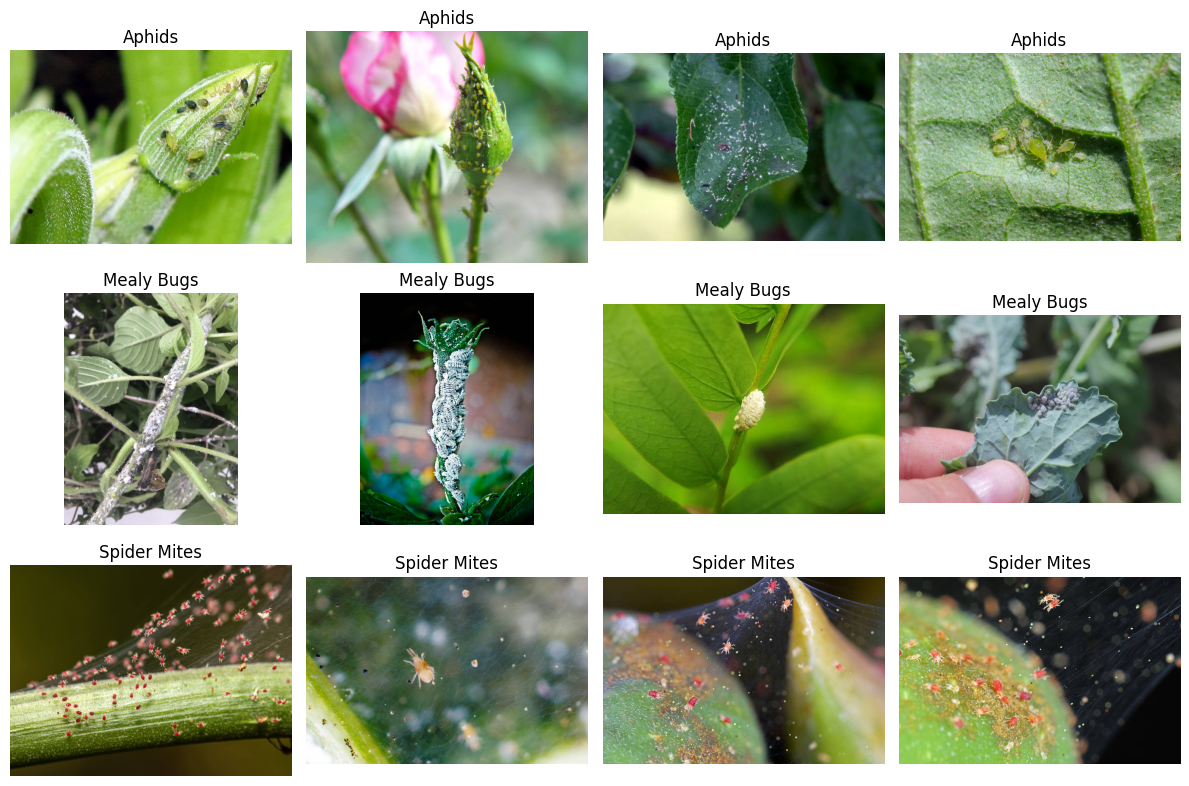

In [6]:
# Inspect training samples before fitting.
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for row, label in enumerate(classes):
    sample = df[(df.label == label) & (df.split == 'train')].sample(4, random_state=SEED)
    for ax, path in zip(axes[row], sample.path):
        with Image.open(path) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
        ax.set_title(label); ax.axis('off')
plt.tight_layout(); plt.show()

### **Frozen VGG16 feature extraction**
Use 224 × 224 RGB inputs and the VGG16-specific preprocessing function. Global average pooling produces 512 features per image. Only training images receive extra augmented views; validation and test images are not augmented.

In [7]:
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras import layers
SIZE = (224, 224)
BATCH = 16
AUGMENTED_VIEWS = 3
backbone = VGG16(weights='imagenet', include_top=False, pooling='avg', input_shape=(*SIZE,3))
backbone.trainable = False
augment = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical', seed=SEED),
    layers.RandomRotation(0.08, fill_mode='reflect', seed=SEED+1),
    layers.RandomZoom((-0.1, 0.1), fill_mode='reflect', seed=SEED+2),
    layers.RandomBrightness(0.12, value_range=(0,255), seed=SEED+3),
    layers.RandomContrast(0.12, seed=SEED+4),
])
def load_image(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert('RGB').resize(SIZE, Image.Resampling.BILINEAR)
        return np.asarray(im, dtype=np.float32)

def extract(part, extra_views=0):
    images = np.stack([load_image(p) for p in part.path])
    labels = part.label.to_numpy()
    features = []
    for view in range(extra_views+1):
        chunks = []
        for start in range(0, len(images), BATCH):
            batch = tf.convert_to_tensor(images[start:start+BATCH])
            if view:
                batch = tf.clip_by_value(augment(batch, training=True), 0, 255)
            chunks.append(backbone(preprocess_input(batch), training=False).numpy())
        features.append(np.concatenate(chunks))
    return np.concatenate(features), np.tile(labels, extra_views+1)

train = df[df.split == 'train'].reset_index(drop=True)
val = df[df.split == 'val'].reset_index(drop=True)
test = df[df.split == 'test'].reset_index(drop=True)
X_train, y_train = extract(train, AUGMENTED_VIEWS)
X_val, y_val = extract(val)
print('Training:', X_train.shape, 'Validation:', X_val.shape)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training: (1236, 512) Validation: (67, 512)


### **SVM hyperparameter selection**
Fit preprocessing and classifiers on training features only. Rank configurations on validation macro F1, with accuracy as a tie-breaker.

In [8]:
from sklearn.model_selection import ParameterGrid
params = list(ParameterGrid([
    {'kernel':['linear'], 'C':[0.01,0.1,1,10,100]},
    {'kernel':['rbf'], 'C':[0.1,1,10,100], 'gamma':['scale',0.0001,0.001,0.01]}
]))
results, models = [], []
for p in params:
    model = make_pipeline(StandardScaler(), SVC(**p))
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    results.append({**p,'val_macro_f1': f1_score(y_val,pred,average='macro'),
                    'val_accuracy': accuracy_score(y_val,pred)})
    models.append(model)
ranking = pd.DataFrame(results).sort_values(['val_macro_f1','val_accuracy'],ascending=False,kind='stable')
display(ranking)
ranking.to_csv('outputs/validation_results.csv',index=False)
best_index = int(ranking.index[0]); best_model = models[best_index]
print('Selected parameters:', params[best_index])

,C,kernel,val_macro_f1,val_accuracy,gamma
15,10.00,rbf,0.674060,0.671642,0.001
13,10.00,rbf,0.658281,0.656716,scale
19,100.00,rbf,0.657800,0.656716,0.001
17,100.00,rbf,0.657225,0.656716,scale
14,10.00,rbf,0.646527,0.641791,0.0001
9,1.00,rbf,0.632364,0.626866,scale
11,1.00,rbf,0.631348,0.626866,0.001
18,100.00,rbf,0.616080,0.611940,0.0001
1,0.10,linear,0.612993,0.611940,NaN
0,0.01,linear,0.612766,0.611940,NaN


Selected parameters: {'C': 10, 'gamma': 0.001, 'kernel': 'rbf'}


### **Held-out evaluation**
Run this after model selection is complete. Do not tune the model using these test results.

Test accuracy: 0.6307692307692307
Test macro F1: 0.6329633265372901
              precision    recall  f1-score   support

      Aphids       0.52      0.68      0.59        22
  Mealy Bugs       0.69      0.50      0.58        22
Spider Mites       0.75      0.71      0.73        21

    accuracy                           0.63        65
   macro avg       0.65      0.63      0.63        65
weighted avg       0.65      0.63      0.63        65



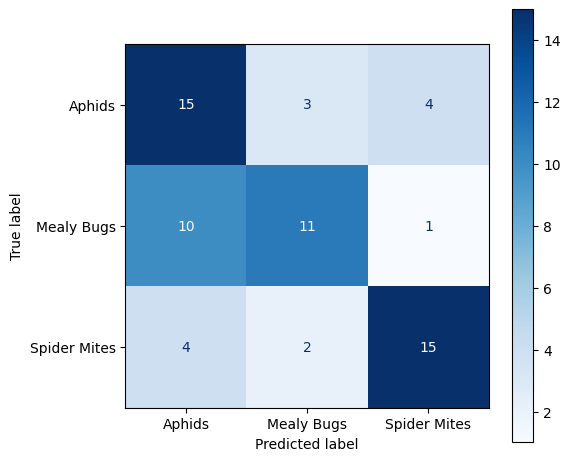

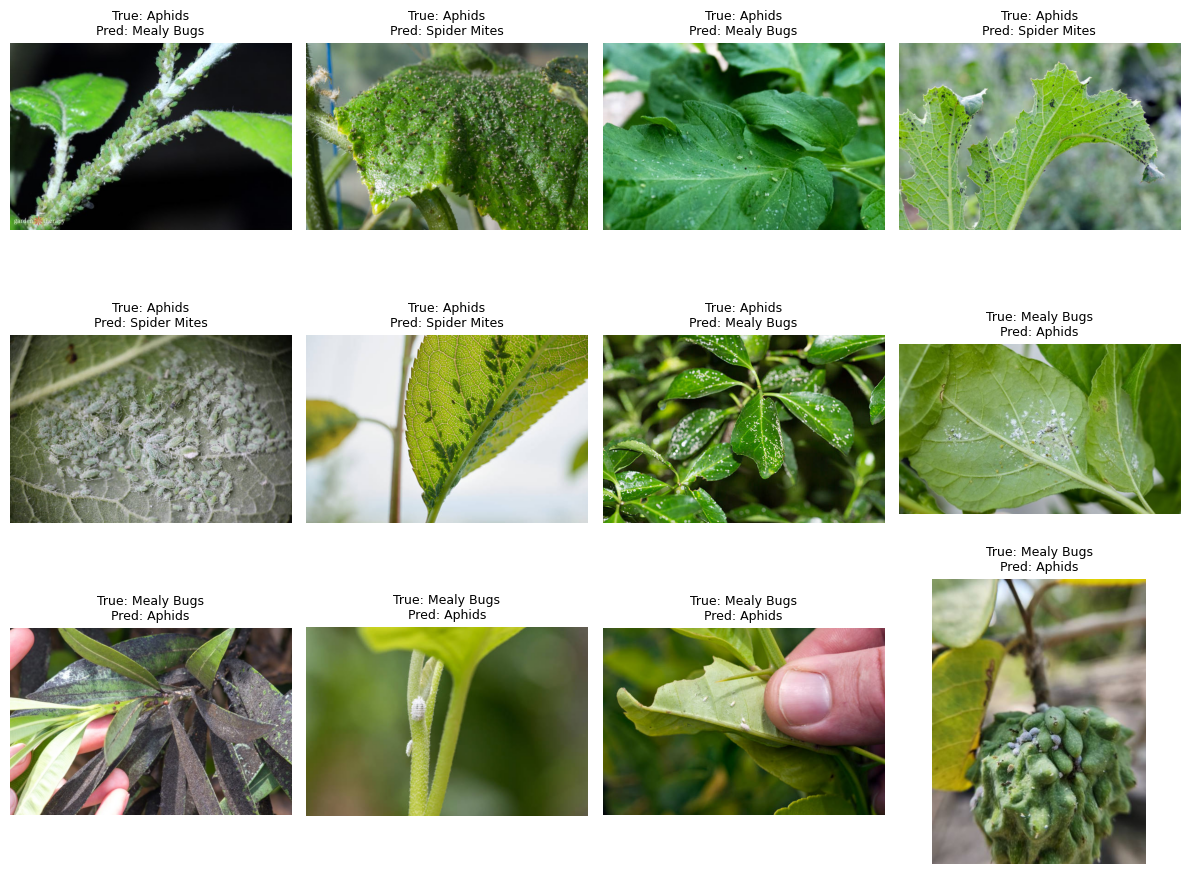

In [9]:
X_test, y_test = extract(test)
y_pred = best_model.predict(X_test)
print('Test accuracy:', accuracy_score(y_test, y_pred))
print('Test macro F1:', f1_score(y_test, y_pred, average='macro'))
print(classification_report(y_test, y_pred, labels=classes, zero_division=0))
report = classification_report(y_test, y_pred, labels=classes, zero_division=0, output_dict=True)
pd.DataFrame(report).T.to_csv('outputs/test_classification_report.csv')
fig, ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,labels=classes,cmap='Blues',ax=ax)
fig.tight_layout(); fig.savefig('outputs/confusion_matrix.png',dpi=200); plt.show()
predictions = test.copy(); predictions['prediction'] = y_pred
predictions.to_csv('outputs/test_predictions.csv',index=False)
wrong = predictions[predictions.label != predictions.prediction]
if len(wrong):
    n = min(12,len(wrong)); fig, axes = plt.subplots((n+3)//4,4,figsize=(12,3*((n+3)//4)),squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax,(_,r) in zip(axes.flat, wrong.head(n).iterrows()):
        with Image.open(r.path) as im: ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
        ax.set_title(f'True: {r.label}\nPred: {r.prediction}',fontsize=9)
    fig.tight_layout(); fig.savefig('outputs/misclassified_examples.png',dpi=160); plt.show()
else: print('No misclassified test images.')

In [10]:
# Save trained SVM pipeline and inference configuration.
joblib.dump(best_model, 'outputs/pest_svm.joblib')
config = {'classes':classes,'backbone':'VGG16','weights':'imagenet','pooling':'avg',
          'image_size':list(SIZE),'seed':SEED,'augmented_views':AUGMENTED_VIEWS,
          'selected_parameters':params[best_index]}
Path('outputs/config.json').write_text(json.dumps(config,indent=2))
import shutil
shutil.make_archive('plant_pest_results','zip','outputs')
from google.colab import files
files.download('plant_pest_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### **Single-image inference test**
This classifier is closed-set: it always chooses one of the three categories. SVM decision scores are not probabilities. Do not treat them as calibrated confidence or as proof of an infestation.

## Model 2: VGG16 + Dense Classifier (Unregularized Baseline)

In [11]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Use only original training images
X_train_base = X_train[:len(train)]
y_train_base = y_train[:len(train)]

assert np.array_equal(
    y_train_base, train.label.to_numpy()
)

# Encode class labels as integers
encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train_base)
y_val_encoded = encoder.transform(y_val)

# Standardize features using training data only
scaler = StandardScaler()

X_train_base_scaled = scaler.fit_transform(X_train_base)
X_val_base_scaled = scaler.transform(X_val)

print("Training features:", X_train_base_scaled.shape)
print("Validation features:", X_val_base_scaled.shape)
print("Classes:", encoder.classes_)

Training features: (309, 512)
Validation features: (67, 512)
Classes: ['Aphids' 'Mealy Bugs' 'Spider Mites']


In [12]:
tf.keras.utils.set_random_seed(SEED)

baseline_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(512,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

baseline_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,051 (258.01 KB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
baseline_history = baseline_model.fit(
    X_train_base_scaled,
    y_train_encoded,
    validation_data=(
        X_val_base_scaled,
        y_val_encoded
    ),
    epochs=25,
    batch_size=16,
    verbose=1
)

Epoch 1/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 98ms/step - accuracy: 0.4757 - loss: 1.1279 - val_accuracy: 0.5672 - val_loss: 0.9779
Epoch 2/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8738 - loss: 0.3584 - val_accuracy: 0.6418 - val_loss: 0.8527
Epoch 3/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9644 - loss: 0.2073 - val_accuracy: 0.6119 - val_loss: 0.8508
Epoch 4/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9806 - loss: 0.1445 - val_accuracy: 0.6567 - val_loss: 0.8437
Epoch 5/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9871 - loss: 0.1068 - val_accuracy: 0.6716 - val_loss: 0.8424
Epoch 6/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9968 - loss: 0.0817 - val_accuracy: 0.6716 - val_loss: 0.8411
Epoch 7/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9968 - loss: 0.0641 - val_accuracy: 0.6866 - val_loss: 0.8433
Epoch 8/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 0.0513 - val_accuracy: 0.6866 - val_loss

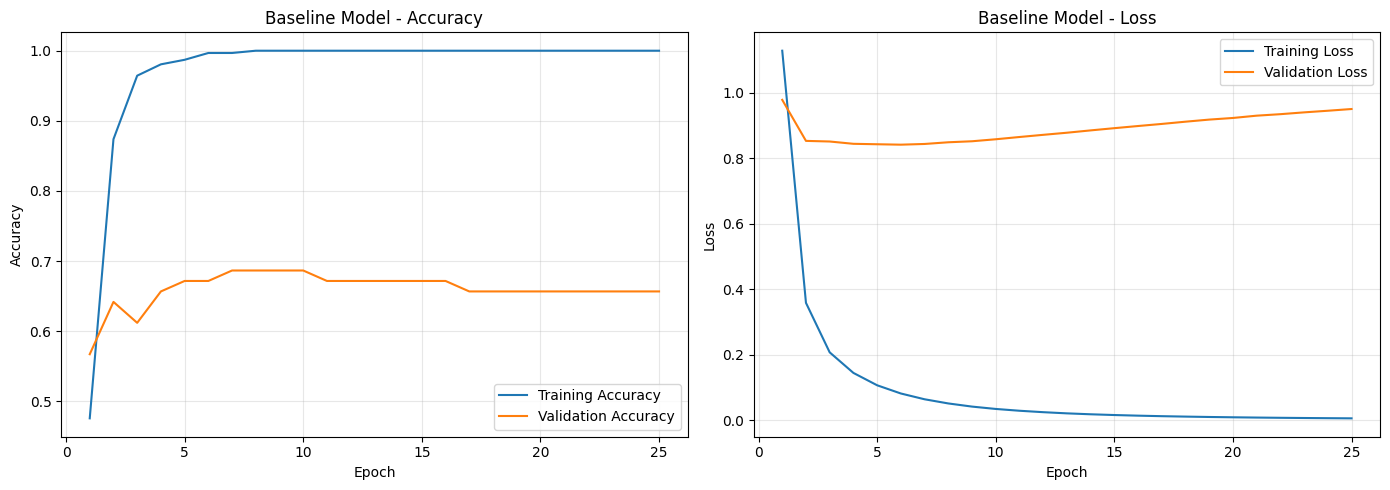

In [15]:
history = baseline_history.history

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, len(history['accuracy']) + 1)

# Accuracy
axes[0].plot(epochs, history['accuracy'],
             label='Training Accuracy')
axes[0].plot(epochs, history['val_accuracy'],
             label='Validation Accuracy')
axes[0].set_title('Baseline Model - Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(epochs, history['loss'],
             label='Training Loss')
axes[1].plot(epochs, history['val_loss'],
             label='Validation Loss')
axes[1].set_title('Baseline Model - Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/baseline_learning_curves.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [16]:
from sklearn.metrics import f1_score

baseline_val_pred = np.argmax(
    baseline_model.predict(X_val_base_scaled, verbose=0),
    axis=1
)

baseline_val_f1 = f1_score(
    y_val_encoded,
    baseline_val_pred,
    average='macro'
)

print("Baseline validation macro F1:", baseline_val_f1)

baseline_model.save('outputs/baseline_model.keras')

joblib.dump(scaler, 'outputs/dense_scaler.joblib')
joblib.dump(encoder, 'outputs/label_encoder.joblib')

pd.DataFrame(baseline_history.history).to_csv(
    'outputs/baseline_history.csv',
    index=False
)

Baseline validation macro F1: 0.6568840579710145


## VGG16 + Dense Classifier (Regularized Model)

In [17]:
X_train_reg = X_train.copy()

y_train_reg_encoded = encoder.transform(y_train)

# Use the same scaler as the baseline
X_train_reg_scaled = scaler.transform(X_train_reg)

print("Original training samples:", len(X_train_base))
print("Additional augmented samples:",
      len(X_train_reg) - len(X_train_base))
print("Total training samples:", len(X_train_reg))
print("Validation samples:", len(X_val_base_scaled))
print("Training feature shape:", X_train_reg_scaled.shape)

Original training samples: 309
Additional augmented samples: 927
Total training samples: 1236
Validation samples: 67
Training feature shape: (1236, 512)


In [18]:
tf.keras.utils.set_random_seed(SEED)

regularized_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(512,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation='softmax')
])

regularized_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

regularized_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,051 (258.01 KB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

regularized_history = regularized_model.fit(
    X_train_reg_scaled,
    y_train_reg_encoded,
    validation_data=(
        X_val_base_scaled,
        y_val_encoded
    ),
    epochs=25,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/25
78/78 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.6570 - loss: 0.8112 - val_accuracy: 0.5821 - val_loss: 1.0604
Epoch 2/25
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8883 - loss: 0.3169 - val_accuracy: 0.5672 - val_loss: 1.1046
Epoch 3/25
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9442 - loss: 0.1834 - val_accuracy: 0.5821 - val_loss: 1.0626
Epoch 4/25
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9620 - loss: 0.1307 - val_accuracy: 0.6119 - val_loss: 1.1942
Epoch 5/25
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9830 - loss: 0.0947 - val_accuracy: 0.6119 - val_loss: 1.1147
Epoch 6/25
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9903 - loss: 0.0666 - val_accuracy: 0.6269 - val_loss: 1.1731
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 1.


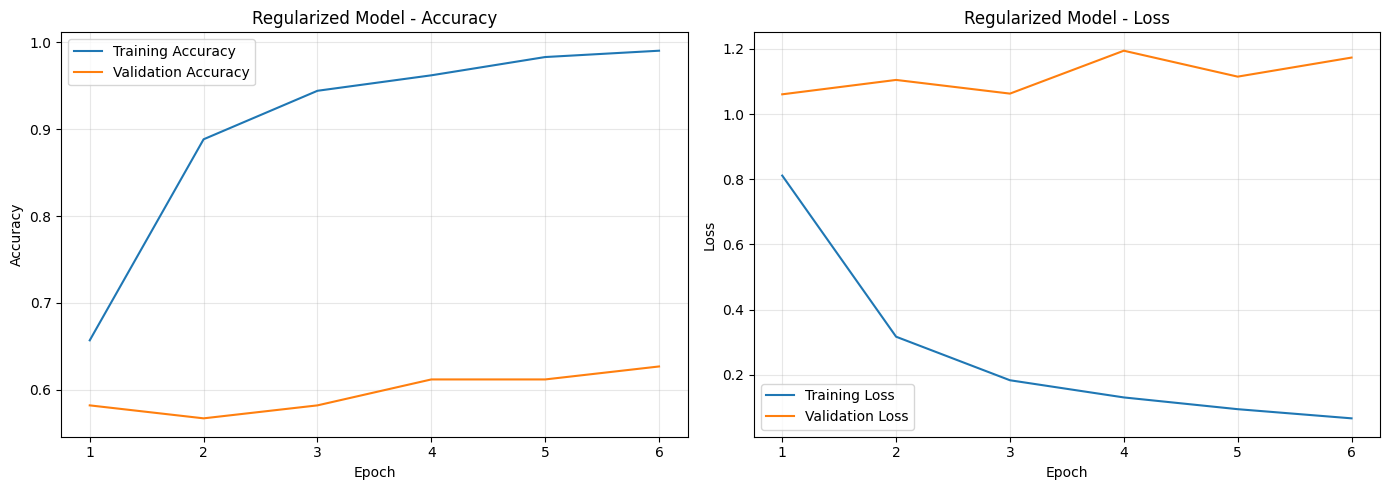

In [20]:
history = regularized_history.history
epochs = range(1, len(history['accuracy']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(epochs, history['accuracy'],
             label='Training Accuracy')
axes[0].plot(epochs, history['val_accuracy'],
             label='Validation Accuracy')
axes[0].set_title('Regularized Model - Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(epochs, history['loss'],
             label='Training Loss')
axes[1].plot(epochs, history['val_loss'],
             label='Validation Loss')
axes[1].set_title('Regularized Model - Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/regularized_learning_curves.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [21]:
reg_val_loss, reg_val_acc = regularized_model.evaluate(
    X_val_base_scaled,
    y_val_encoded,
    verbose=0
)

reg_val_pred = np.argmax(
    regularized_model.predict(
        X_val_base_scaled, verbose=0
    ),
    axis=1
)

reg_val_f1 = f1_score(
    y_val_encoded,
    reg_val_pred,
    average='macro'
)

print(f"Validation accuracy: {reg_val_acc:.4f}")
print(f"Validation loss: {reg_val_loss:.4f}")
print(f"Validation macro F1: {reg_val_f1:.4f}")

regularized_model.save(
    'outputs/regularized_model.keras'
)

pd.DataFrame(regularized_history.history).to_csv(
    'outputs/regularized_history.csv',
    index=False
)

Validation accuracy: 0.5821
Validation loss: 1.0604
Validation macro F1: 0.5840


## VGG16 + Dense Classifier (Regularization Without Augmentation)

In [22]:
tf.keras.utils.set_random_seed(SEED)

dropout_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(512,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation='softmax')
])

dropout_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

dropout_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,051 (258.01 KB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
dropout_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

dropout_history = dropout_model.fit(
    X_train_base_scaled,
    y_train_encoded,
    validation_data=(
        X_val_base_scaled,
        y_val_encoded
    ),
    epochs=25,
    batch_size=16,
    callbacks=[dropout_early_stopping],
    verbose=1
)

Epoch 1/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - accuracy: 0.4045 - loss: 1.3887 - val_accuracy: 0.4776 - val_loss: 1.1045
Epoch 2/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8091 - loss: 0.4910 - val_accuracy: 0.5522 - val_loss: 0.9787
Epoch 3/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8997 - loss: 0.3218 - val_accuracy: 0.6269 - val_loss: 0.9175
Epoch 4/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9256 - loss: 0.2538 - val_accuracy: 0.5821 - val_loss: 0.9230
Epoch 5/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9450 - loss: 0.2058 - val_accuracy: 0.5970 - val_loss: 0.9162
Epoch 6/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9741 - loss: 0.1405 - val_accuracy: 0.5970 - val_loss: 0.9254
Epoch 7/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9806 - loss: 0.1333 - val_accuracy: 0.5970 - val_loss: 0.9108
Epoch 8/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9773 - loss: 0.1005 - val_accuracy: 0.6269 - val_loss

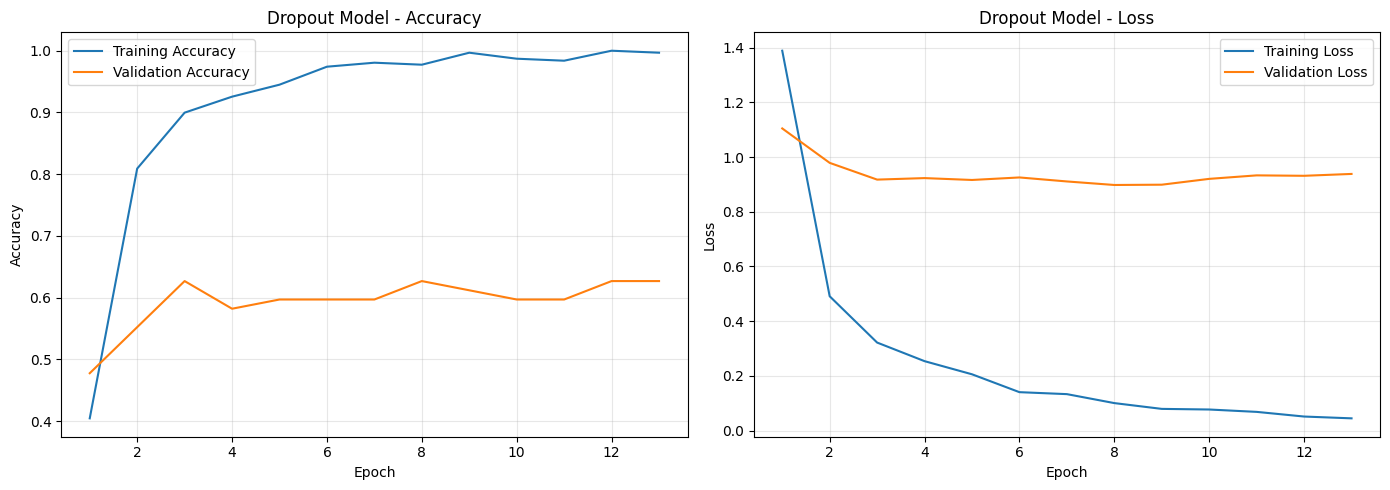

In [27]:
history = dropout_history.history
epochs = range(1, len(history['accuracy']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(epochs, history['accuracy'],
             label='Training Accuracy')
axes[0].plot(epochs, history['val_accuracy'],
             label='Validation Accuracy')
axes[0].set_title('Dropout Model - Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(epochs, history['loss'],
             label='Training Loss')
axes[1].plot(epochs, history['val_loss'],
             label='Validation Loss')
axes[1].set_title('Dropout Model - Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/dropout_learning_curves.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [24]:
dropout_val_loss, dropout_val_acc = dropout_model.evaluate(
    X_val_base_scaled,
    y_val_encoded,
    verbose=0
)

dropout_val_pred = np.argmax(
    dropout_model.predict(
        X_val_base_scaled, verbose=0
    ),
    axis=1
)

dropout_val_f1 = f1_score(
    y_val_encoded,
    dropout_val_pred,
    average='macro'
)

comparison = pd.DataFrame([
    {
        'Model': 'VGG16 + SVM',
        'Validation Accuracy': 0.671642,
        'Validation Macro F1': 0.674060
    },
    {
        'Model': 'Unregularized Dense',
        'Validation Accuracy': baseline_history.history[
            'val_accuracy'
        ][-1],
        'Validation Macro F1': baseline_val_f1
    },
    {
        'Model': 'Dropout + Augmentation + Early Stopping',
        'Validation Accuracy': reg_val_acc,
        'Validation Macro F1': reg_val_f1
    },
    {
        'Model': 'Dropout + Early Stopping',
        'Validation Accuracy': dropout_val_acc,
        'Validation Macro F1': dropout_val_f1
    }
])

display(comparison.sort_values(
    'Validation Macro F1',
    ascending=False
))

,Model,Validation Accuracy,Validation Macro F1
0,VGG16 + SVM,0.671642,0.674060
1,Unregularized Dense,0.656716,0.656884
3,Dropout + Early Stopping,0.626866,0.627141
2,Dropout + Augmentation + Early Stopping,0.582090,0.584010


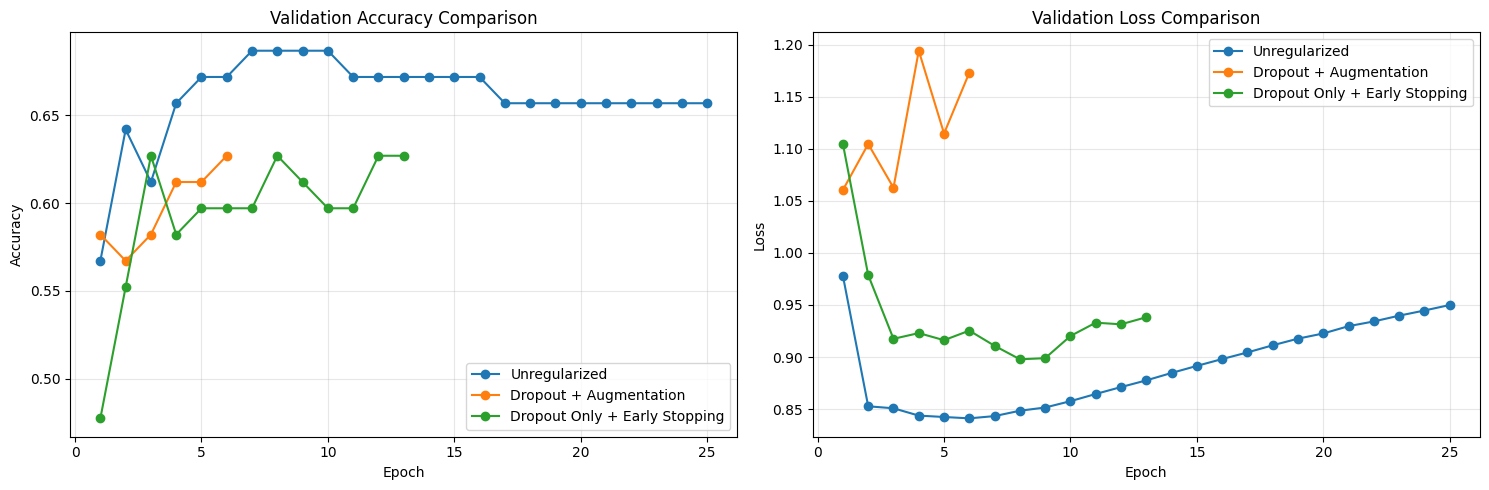

In [25]:
histories = {
    'Unregularized': baseline_history.history,
    'Dropout + Augmentation': regularized_history.history,
    'Dropout Only + Early Stopping': dropout_history.history
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, hist in histories.items():

    epochs = range(1, len(hist['val_accuracy']) + 1)

    axes[0].plot(
        epochs,
        hist['val_accuracy'],
        marker='o',
        label=name
    )

    axes[1].plot(
        epochs,
        hist['val_loss'],
        marker='o',
        label=name
    )

axes[0].set_title('Validation Accuracy Comparison')
axes[0].set_ylabel('Accuracy')

axes[1].set_title('Validation Loss Comparison')
axes[1].set_ylabel('Loss')

for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    'outputs/validation_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [26]:
dropout_model.save('outputs/dropout_model.keras')

pd.DataFrame(dropout_history.history).to_csv(
    'outputs/dropout_history.csv',
    index=False
)

comparison.to_csv(
    'outputs/model_comparison.csv',
    index=False
)

print("Latest model and comparison results saved.")

Latest model and comparison results saved.


## Fine-Tuned VGG16 Model

In [28]:
X_train_images = np.stack([
    load_image(p) for p in train.path
])

X_val_images = np.stack([
    load_image(p) for p in val.path
])

# Apply VGG16-specific preprocessing
X_train_images = preprocess_input(X_train_images)
X_val_images = preprocess_input(X_val_images)

print("Training images:", X_train_images.shape)
print("Validation images:", X_val_images.shape)

Training images: (309, 224, 224, 3)
Validation images: (67, 224, 224, 3)


In [29]:
tf.keras.utils.set_random_seed(SEED)

finetune_backbone = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3),
    pooling='avg'
)

finetune_backbone.trainable = False

finetune_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    finetune_backbone,
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

finetune_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

finetune_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 512)            │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,739 (56.38 MB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [30]:
warmup_history = finetune_model.fit(
    X_train_images,
    y_train_encoded,
    validation_data=(
        X_val_images,
        y_val_encoded
    ),
    epochs=15,
    batch_size=16,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=4,
            restore_best_weights=True
        )
    ],
    verbose=1
)

finetune_model.save('outputs/vgg16_warmup.keras')

Epoch 1/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 36s 798ms/step - accuracy: 0.4984 - loss: 1.8156 - val_accuracy: 0.4925 - val_loss: 1.7758
Epoch 2/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.8026 - loss: 0.4952 - val_accuracy: 0.5075 - val_loss: 1.8087
Epoch 3/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - accuracy: 0.8414 - loss: 0.3936 - val_accuracy: 0.4627 - val_loss: 2.5129
Epoch 4/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - accuracy: 0.8511 - loss: 0.4000 - val_accuracy: 0.4925 - val_loss: 1.8699
Epoch 5/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 84ms/step - accuracy: 0.8511 - loss: 0.3554 - val_accuracy: 0.6119 - val_loss: 1.3295
Epoch 6/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - accuracy: 0.9191 - loss: 0.1886 - val_accuracy: 0.5970 - val_loss: 1.5840
Epoch 7/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - accuracy: 0.9385 - loss: 0.1481 - val_accuracy: 0.6119 - val_loss: 1.5237
Epoch 8/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - accuracy: 0.9935 - loss: 0.0514 - val_accuracy: 0.5821 

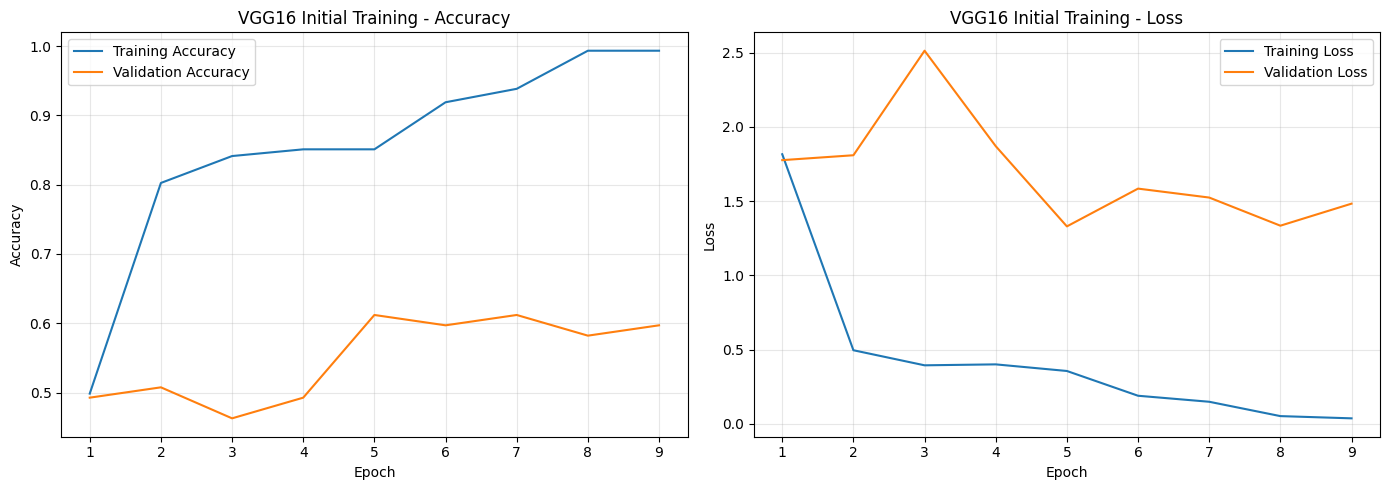

In [31]:
history = warmup_history.history
epochs = range(1, len(history['accuracy']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(epochs, history['accuracy'],
             label='Training Accuracy')
axes[0].plot(epochs, history['val_accuracy'],
             label='Validation Accuracy')
axes[0].set_title('VGG16 Initial Training - Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(epochs, history['loss'],
             label='Training Loss')
axes[1].plot(epochs, history['val_loss'],
             label='Validation Loss')
axes[1].set_title('VGG16 Initial Training - Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/vgg16_warmup_curves.png',
            dpi=300, bbox_inches='tight')
plt.show()

### Fine-Tuning VGG16 — Block 5

In [32]:
# Record validation performance before fine-tuning
warmup_val_loss, warmup_val_acc = finetune_model.evaluate(
    X_val_images,
    y_val_encoded,
    verbose=0
)

warmup_val_pred = np.argmax(
    finetune_model.predict(X_val_images, verbose=0),
    axis=1
)

warmup_val_f1 = f1_score(
    y_val_encoded,
    warmup_val_pred,
    average='macro'
)

pd.DataFrame(warmup_history.history).to_csv(
    'outputs/vgg16_warmup_history.csv',
    index=False
)

# Enable fine-tuning
finetune_backbone.trainable = True

# Only unfreeze Block 5
for layer in finetune_backbone.layers:
    layer.trainable = layer.name.startswith('block5')

# Recompile with a smaller learning rate
finetune_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

for layer in finetune_backbone.layers:
    print(layer.name, "Trainable:", layer.trainable)

finetune_model.summary()

input_layer_5 Trainable: False
block1_conv1 Trainable: False
block1_conv2 Trainable: False
block1_pool Trainable: False
block2_conv1 Trainable: False
block2_conv2 Trainable: False
block2_pool Trainable: False
block3_conv1 Trainable: False
block3_conv2 Trainable: False
block3_conv3 Trainable: False
block3_pool Trainable: False
block4_conv1 Trainable: False
block4_conv2 Trainable: False
block4_conv3 Trainable: False
block4_pool Trainable: False
block5_conv1 Trainable: True
block5_conv2 Trainable: True
block5_conv3 Trainable: True
block5_pool Trainable: True
global_average_pooling2d_1 Trainable: False


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 512)            │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,739 (56.38 MB)

 Trainable params: 7,145,475 (27.26 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [33]:
finetune_history = finetune_model.fit(
    X_train_images,
    y_train_encoded,

    validation_data=(
        X_val_images,
        y_val_encoded
    ),

    epochs=15,
    batch_size=16,

    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=4,
            restore_best_weights=True,
            verbose=1
        )
    ],

    verbose=1
)

Epoch 1/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 384ms/step - accuracy: 0.9579 - loss: 0.1300 - val_accuracy: 0.6866 - val_loss: 1.3606
Epoch 2/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - accuracy: 0.9838 - loss: 0.0543 - val_accuracy: 0.6119 - val_loss: 1.5733
Epoch 3/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - accuracy: 1.0000 - loss: 0.0165 - val_accuracy: 0.6567 - val_loss: 1.4492
Epoch 4/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - accuracy: 1.0000 - loss: 0.0098 - val_accuracy: 0.6269 - val_loss: 1.5464
Epoch 5/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step - accuracy: 1.0000 - loss: 0.0066 - val_accuracy: 0.6269 - val_loss: 1.6091
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 1.


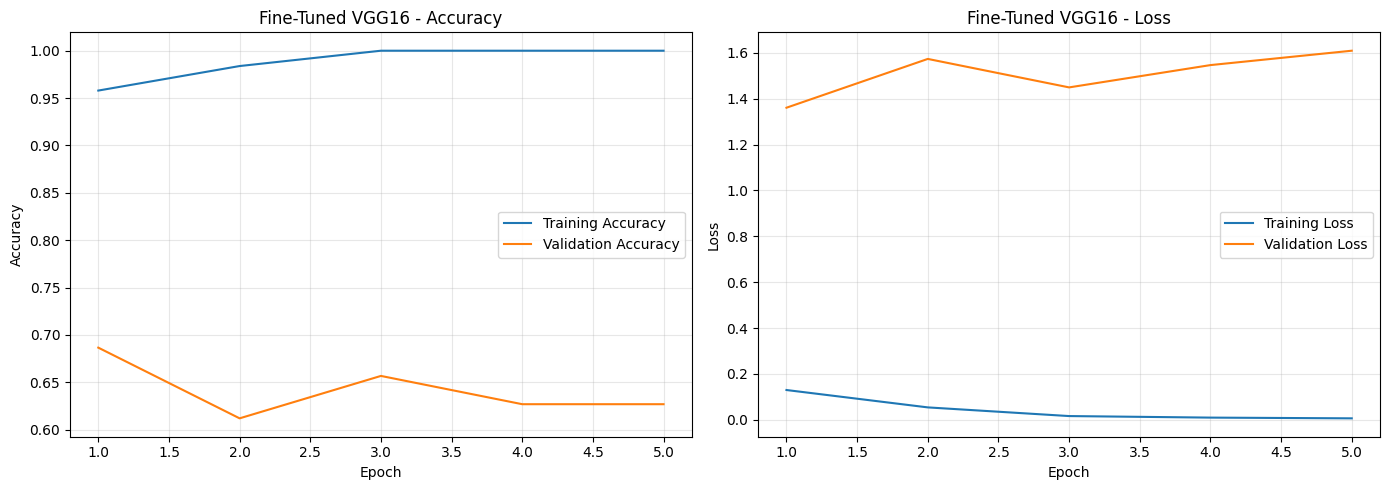

In [34]:
history = finetune_history.history
epochs = range(1, len(history['accuracy']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(epochs, history['accuracy'],
             label='Training Accuracy')
axes[0].plot(epochs, history['val_accuracy'],
             label='Validation Accuracy')
axes[0].set_title('Fine-Tuned VGG16 - Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(epochs, history['loss'],
             label='Training Loss')
axes[1].plot(epochs, history['val_loss'],
             label='Validation Loss')
axes[1].set_title('Fine-Tuned VGG16 - Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig('outputs/vgg16_finetuned_curves.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [35]:
finetune_val_loss, finetune_val_acc = finetune_model.evaluate(
    X_val_images,
    y_val_encoded,
    verbose=0
)

finetune_val_pred = np.argmax(
    finetune_model.predict(X_val_images, verbose=0),
    axis=1
)

finetune_val_f1 = f1_score(
    y_val_encoded,
    finetune_val_pred,
    average='macro'
)

print(f"Validation accuracy: {finetune_val_acc:.4f}")
print(f"Validation loss: {finetune_val_loss:.4f}")
print(f"Validation macro F1: {finetune_val_f1:.4f}")

finetune_model.save('outputs/vgg16_finetuned.keras')

pd.DataFrame(finetune_history.history).to_csv(
    'outputs/vgg16_finetuned_history.csv',
    index=False
)

Validation accuracy: 0.6866
Validation loss: 1.3606
Validation macro F1: 0.6857


## Final Model Comparison and Selection

In [36]:
final_comparison = pd.concat([
    comparison,
    pd.DataFrame([
        {
            'Model': 'VGG16 Warmup',
            'Validation Accuracy': warmup_val_acc,
            'Validation Macro F1': warmup_val_f1
        },
        {
            'Model': 'Fine-Tuned VGG16',
            'Validation Accuracy': finetune_val_acc,
            'Validation Macro F1': finetune_val_f1
        }
    ])
], ignore_index=True)

final_comparison = final_comparison.sort_values(
    'Validation Macro F1',
    ascending=False
).reset_index(drop=True)

display(final_comparison)

final_comparison.to_csv(
    'outputs/final_model_comparison.csv',
    index=False
)

# Save dropout-only experiment if not already saved
dropout_model.save('outputs/dropout_model.keras')

pd.DataFrame(dropout_history.history).to_csv(
    'outputs/dropout_history.csv',
    index=False
)

,Model,Validation Accuracy,Validation Macro F1
0,Fine-Tuned VGG16,0.686567,0.685704
1,VGG16 + SVM,0.671642,0.674060
2,Unregularized Dense,0.656716,0.656884
3,Dropout + Early Stopping,0.626866,0.627141
4,VGG16 Warmup,0.611940,0.611280
5,Dropout + Augmentation + Early Stopping,0.582090,0.584010


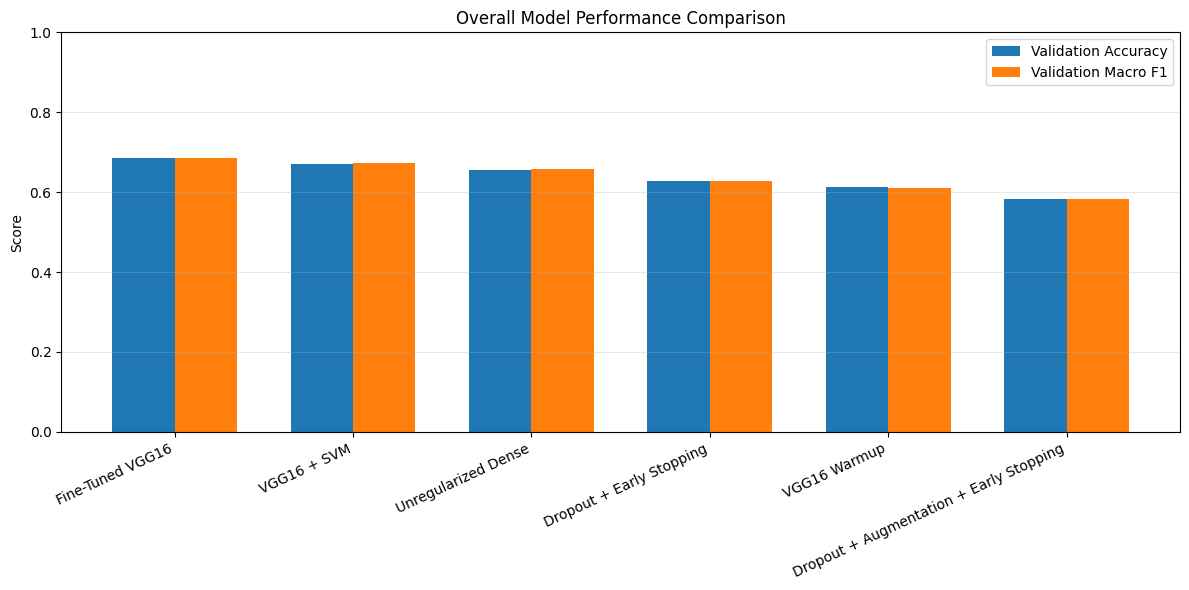

In [37]:
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(final_comparison))
width = 0.35

ax.bar(
    x - width/2,
    final_comparison['Validation Accuracy'],
    width,
    label='Validation Accuracy'
)

ax.bar(
    x + width/2,
    final_comparison['Validation Macro F1'],
    width,
    label='Validation Macro F1'
)

ax.set_xticks(x)
ax.set_xticklabels(
    final_comparison['Model'],
    rotation=25,
    ha='right'
)

ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.set_title('Overall Model Performance Comparison')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig(
    'outputs/final_model_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## Final Model Evaluation on the Test Dataset

In [38]:
X_test_images = np.stack([
    load_image(p) for p in test.path
])

X_test_images = preprocess_input(X_test_images)

y_test_encoded = encoder.transform(
    test.label.to_numpy()
)

print("Testing images:", X_test_images.shape)
print("Testing labels:", y_test_encoded.shape)

Testing images: (65, 224, 224, 3)
Testing labels: (65,)


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

test_loss, test_acc = finetune_model.evaluate(
    X_test_images,
    y_test_encoded,
    verbose=0
)

test_probabilities = finetune_model.predict(
    X_test_images,
    verbose=0
)

test_predictions = np.argmax(
    test_probabilities,
    axis=1
)

test_precision = precision_score(
    y_test_encoded,
    test_predictions,
    average='macro',
    zero_division=0
)

test_recall = recall_score(
    y_test_encoded,
    test_predictions,
    average='macro',
    zero_division=0
)

test_f1 = f1_score(
    y_test_encoded,
    test_predictions,
    average='macro'
)

print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Test Loss:      {test_loss:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")
print(f"Test Macro F1:  {test_f1:.4f}")

print("\nClassification Report:\n")

print(classification_report(
    y_test_encoded,
    test_predictions,
    target_names=encoder.classes_,
    zero_division=0
))

Test Accuracy:  0.6308
Test Loss:      0.9741
Test Precision: 0.6692
Test Recall:    0.6342
Test Macro F1:  0.6200

Classification Report:

              precision    recall  f1-score   support

      Aphids       0.61      0.64      0.62        22
  Mealy Bugs       0.82      0.41      0.55        22
Spider Mites       0.58      0.86      0.69        21

    accuracy                           0.63        65
   macro avg       0.67      0.63      0.62        65
weighted avg       0.67      0.63      0.62        65



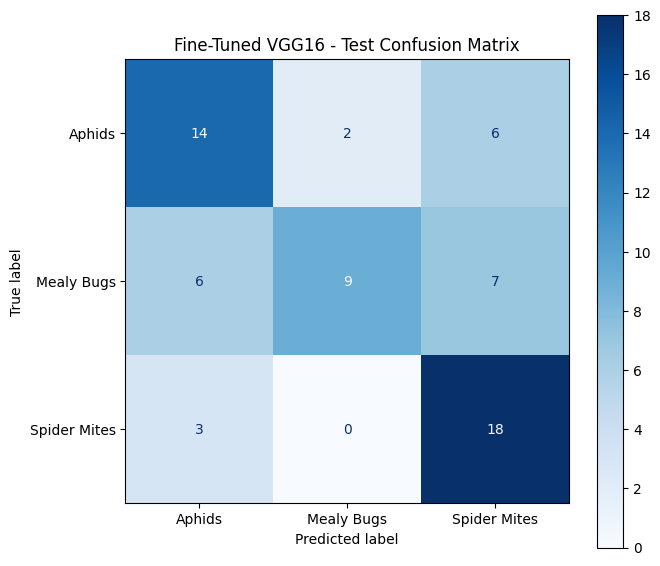

In [40]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    y_test_encoded,
    test_predictions,
    labels=np.arange(len(encoder.classes_))
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

disp.plot(
    ax=ax,
    cmap='Blues',
    values_format='d'
)

plt.title('Fine-Tuned VGG16 - Test Confusion Matrix')
plt.tight_layout()

plt.savefig(
    'outputs/final_confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Total misclassified images: 24


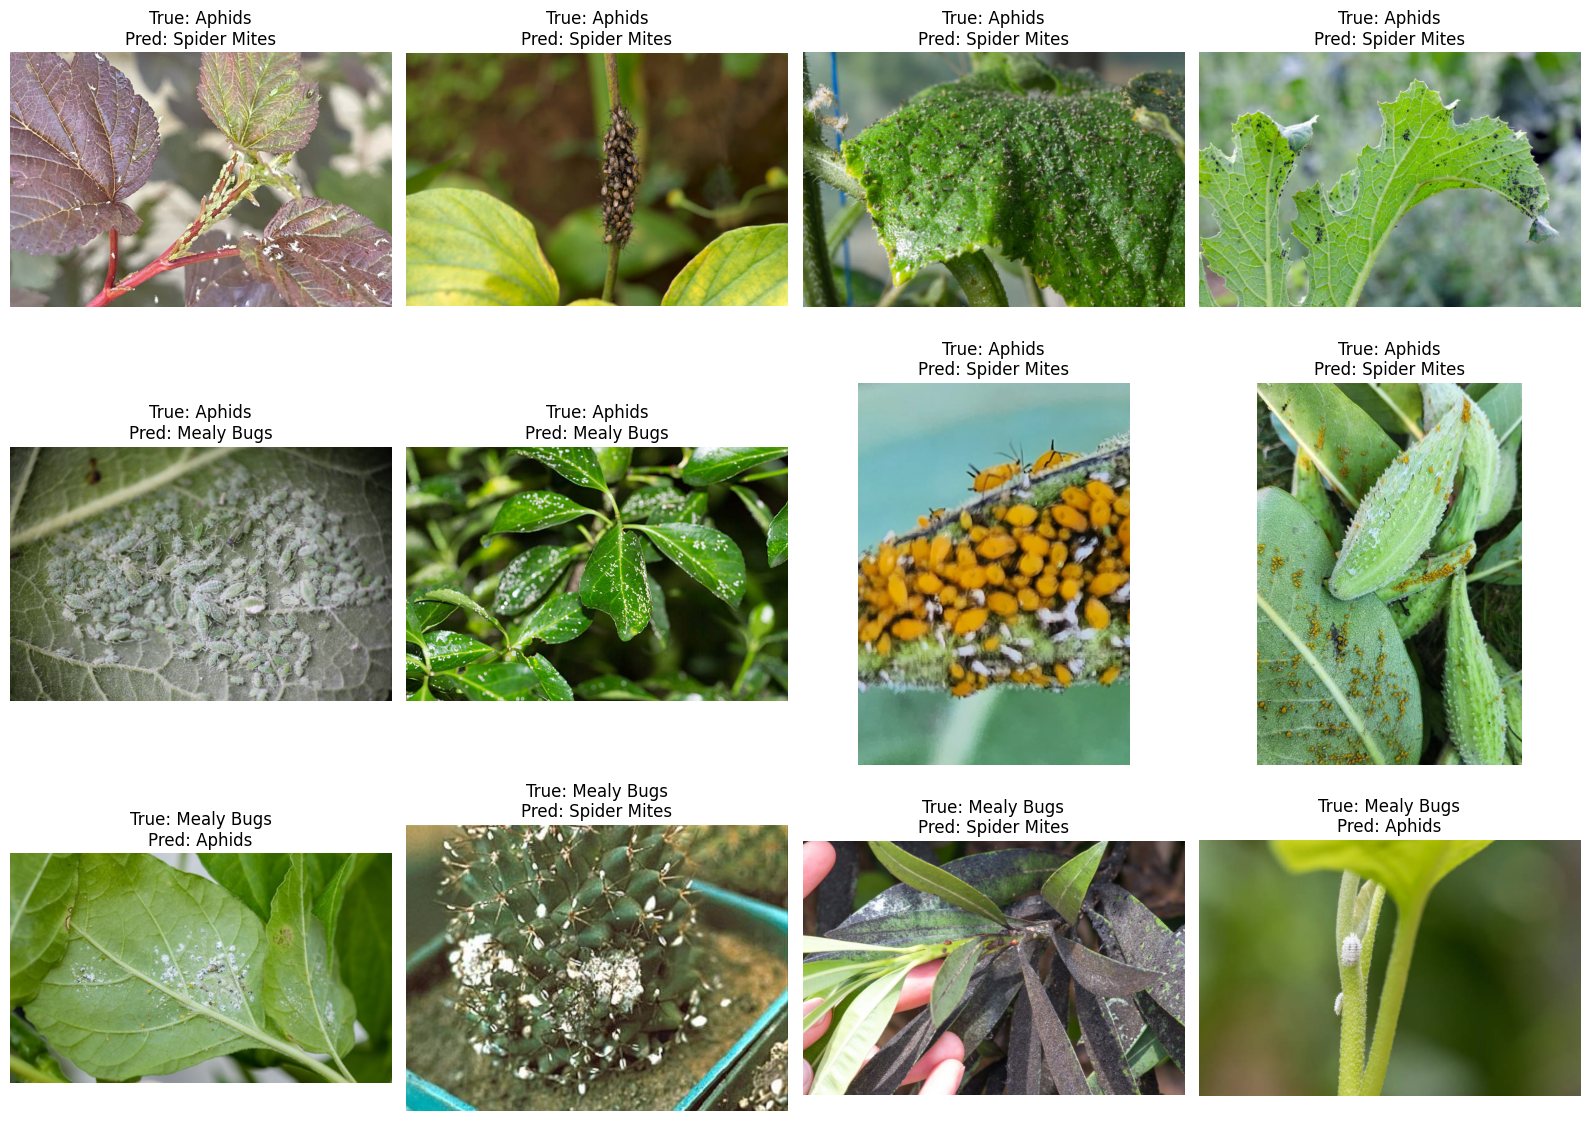

In [41]:
incorrect_indices = np.where(
    test_predictions != y_test_encoded
)[0]

print("Total misclassified images:",
      len(incorrect_indices))

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax in axes:
    ax.axis('off')

for ax, idx in zip(axes, incorrect_indices[:12]):

    with Image.open(test.iloc[idx]['path']) as img:
        img = ImageOps.exif_transpose(img).convert('RGB')
        ax.imshow(img)

    true_label = encoder.classes_[y_test_encoded[idx]]
    predicted_label = encoder.classes_[test_predictions[idx]]

    ax.set_title(
        f"True: {true_label}\n"
        f"Pred: {predicted_label}"
    )

plt.tight_layout()

plt.savefig(
    'outputs/final_misclassified_images.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [42]:
final_metrics = {
    'model': 'Fine-Tuned VGG16',
    'test_accuracy': float(test_acc),
    'test_loss': float(test_loss),
    'test_macro_precision': float(test_precision),
    'test_macro_recall': float(test_recall),
    'test_macro_f1': float(test_f1),
    'test_samples': len(y_test_encoded)
}

Path('outputs/final_metrics.json').write_text(
    json.dumps(final_metrics, indent=2)
)

report = classification_report(
    y_test_encoded,
    test_predictions,
    target_names=encoder.classes_,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    'outputs/final_classification_report.csv'
)

pd.DataFrame(
    cm,
    index=encoder.classes_,
    columns=encoder.classes_
).to_csv('outputs/final_confusion_matrix.csv')

print("Final evaluation results saved.")

Final evaluation results saved.


## Downstream Application — Plant Pest Identifier

In [43]:
!pip -q install gradio

In [44]:
app_config = {
    'classes': encoder.classes_.tolist(),
    'image_size': list(SIZE),
    'model': 'vgg16_finetuned.keras'
}

Path('outputs/app_config.json').write_text(
    json.dumps(app_config, indent=2)
)

print(app_config)

{'classes': ['Aphids', 'Mealy Bugs', 'Spider Mites'], 'image_size': [224, 224], 'model': 'vgg16_finetuned.keras'}


In [45]:
%%writefile app.py

import gradio as gr
import tensorflow as tf
import numpy as np
import json

from pathlib import Path
from PIL import Image, ImageOps
from tensorflow.keras.applications.vgg16 import preprocess_input

# Load configuration and trained model
BASE_DIR = Path(__file__).resolve().parent
OUTPUT_DIR = BASE_DIR / "outputs"

with open(OUTPUT_DIR / "app_config.json") as f:
    config = json.load(f)

classes = config["classes"]
image_size = tuple(config["image_size"])

model = tf.keras.models.load_model(
    OUTPUT_DIR / config["model"],
    compile=False
)

# Pest-specific information
pest_information = {
    "Aphids": {
        "signs": (
            "Small, soft-bodied insects that often "
            "cluster around stems and new growth."
        ),
        "action": (
            "Isolate the plant, inspect new growth and "
            "leaf undersides, and consider rinsing "
            "visible aphids off with water."
        )
    },

    "Mealy Bugs": {
        "signs": (
            "White, waxy or cotton-like insects often "
            "found around leaf joints and stems."
        ),
        "action": (
            "Isolate the plant, inspect leaf joints "
            "and manually remove visible insects "
            "where practical."
        )
    },

    "Spider Mites": {
        "signs": (
            "Tiny mites, fine webbing and small "
            "discoloured spots on leaves."
        ),
        "action": (
            "Isolate the plant, closely inspect leaf "
            "undersides and look for fine webbing. "
            "Consider rinsing affected foliage."
        )
    }
}

# Image preprocessing
def prepare_image(image_path):

    with Image.open(image_path) as image:
        image = ImageOps.exif_transpose(image)
        image = image.convert("RGB")

        image = image.resize(
            image_size,
            Image.Resampling.BILINEAR
        )

        image = np.asarray(image, dtype=np.float32)

    image = np.expand_dims(image, axis=0)

    return preprocess_input(image)


# Prediction and downstream guidance
def identify_pest(image_path):

    if image_path is None:
        return {}, "Please upload a plant photograph."

    image = prepare_image(image_path)

    probabilities = model.predict(
        image, verbose=0
    )[0]

    scores = {
        label: float(score)
        for label, score in zip(classes, probabilities)
    }

    predicted_index = np.argmax(probabilities)
    predicted_class = classes[predicted_index]

    information = pest_information[predicted_class]

    guidance = (
        f"Predicted pest: {predicted_class}\n\n"
        f"Identifying characteristics:\n"
        f"{information['signs']}\n\n"
        f"Suggested next steps:\n"
        f"{information['action']}\n\n"
        "Important: Verify the identifying "
        "characteristics before applying treatment. "
        "The model only recognizes three pest categories "
        "and cannot determine whether a plant is healthy."
    )

    return scores, guidance


# Application interface
demo = gr.Interface(
    fn=identify_pest,

    inputs=gr.Image(
        type="filepath",
        label="Upload a plant photograph"
    ),

    outputs=[
        gr.Label(
            num_top_classes=3,
            label="Predicted Pest — Model Scores"
        ),

        gr.Textbox(
            label="Identification and Suggested Next Steps",
            lines=12
        )
    ],

    title="Common Household Plant Pest Identifier",

    description=(
        "Upload a photograph of a suspected plant pest. "
        "This experimental machine learning model "
        "classifies aphids, mealybugs and spider mites. "
        "Model scores are not calibrated probabilities "
        "of correctness."
    )
)

if __name__ == "__main__":
    demo.launch()

Writing app.py


In [46]:
from app import identify_pest

sample_path = val.iloc[0]['path']

scores, guidance = identify_pest(sample_path)

print("Actual label:", val.iloc[0]['label'])
print("\nModel scores:", scores)
print("\n", guidance)

# Verify exported model predictions
exported_scores = np.array([
    scores[label] for label in encoder.classes_
])

original_scores = finetune_model.predict(
    X_val_images[:1], verbose=0
)[0]

np.testing.assert_allclose(
    exported_scores,
    original_scores,
    rtol=1e-4,
    atol=1e-5
)

print("\nInference consistency check passed.")

Actual label: Aphids

Model scores: {'Aphids': 0.5637486577033997, 'Mealy Bugs': 0.41848114132881165, 'Spider Mites': 0.017770158126950264}

 Predicted pest: Aphids

Identifying characteristics:
Small, soft-bodied insects that often cluster around stems and new growth.

Suggested next steps:
Isolate the plant, inspect new growth and leaf undersides, and consider rinsing visible aphids off with water.

Important: Verify the identifying characteristics before applying treatment. The model only recognizes three pest categories and cannot determine whether a plant is healthy.

Inference consistency check passed.


In [47]:
from app import demo

demo.launch(share=True, inline=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://93ed46715ba009bf8e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Export Final Project Files

In [48]:
import shutil
from google.colab import files

shutil.make_archive(
    'plant_pest_final_results',
    'zip',
    'outputs'
)

files.download('plant_pest_final_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:
files.download('app.py')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
from importlib.metadata import version

packages = [
    'tensorflow',
    'numpy',
    'pandas',
    'scikit-learn',
    'matplotlib',
    'Pillow',
    'joblib',
    'gradio'
]

requirements = '\n'.join([
    f'{package}=={version(package)}'
    for package in packages
])

Path('requirements.txt').write_text(requirements)

print(requirements)

files.download('requirements.txt')

tensorflow==2.21.0
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
Pillow==11.3.0
joblib==1.6.0
gradio==6.31.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>